In [1]:
import numpy as np
import copy
import matplotlib.pyplot as plt
import matplotlib as mpl

In [2]:
import os, sys

class HidePrinting:
    def block(self):
        if not self.blocked:
            self._original_stdout = sys.stdout
            sys.stdout = open(os.devnull, 'w')
            self.blocked = True
    
    def unblock(self):
        if self.blocked:
            sys.stdout.close()
            sys.stdout = self._original_stdout
            sys.stdout.flush()
            self.blocked = False
        
    def __enter__(self):
        self.blocked=True
        self._original_stdout = sys.stdout
        sys.stdout = open(os.devnull, 'w')
        return self
    
    def __exit__(self, exc_type, exc_val, exc_tb):
        self.unblock()

In [3]:
import os
import sys

sys.path.append('Code')
os.environ["STAR_ROUTINES_PATH"] = os.getcwd() + '/Code/'

from star_routines import *

#Making directory for plots
plots_directory = 'Plots'

if not os.path.exists(plots_directory):
    os.mkdir(plots_directory)

In [4]:
solver = Bose_Star_Solver(d=2, l=1.0, kappa=1.0, el=0.0, mass=0.0, phi0=0.5)
solver.shoot_for_omega(omega_range=[1.9,5])

Omega found by shooting 1.4258
Star mass is equal to 0.3430


In [5]:
solver = Bose_Star_Solver(d=2, l=1.0, kappa=1.0, el=0.0, mass=0.0, phi0=0.5)
solver.shoot_for_omega(omega_range=[5,7])

Omega found by shooting 2.0745
Star mass is equal to 0.4971


In [6]:
solver = Bose_Star_Solver(d=3, l=1.0, kappa=1.0, el=1.0, mass=0.0, phi0=0.5)
solver.shoot_for_omega(omega_range=[2,5])

Omega found by shooting 2.7057
Star mass is equal to 0.1455
Star charge is equal to 0.1015


In [7]:
solver = Bose_Star_Solver(d=3, l=1.0, kappa=1.0, el=0.5, mass=0.0, phi0=1.1)
solver.shoot_for_omega(omega_range=[11,12])

Omega found by shooting 2.1599
Star mass is equal to 0.1408
Star charge is equal to 0.0956


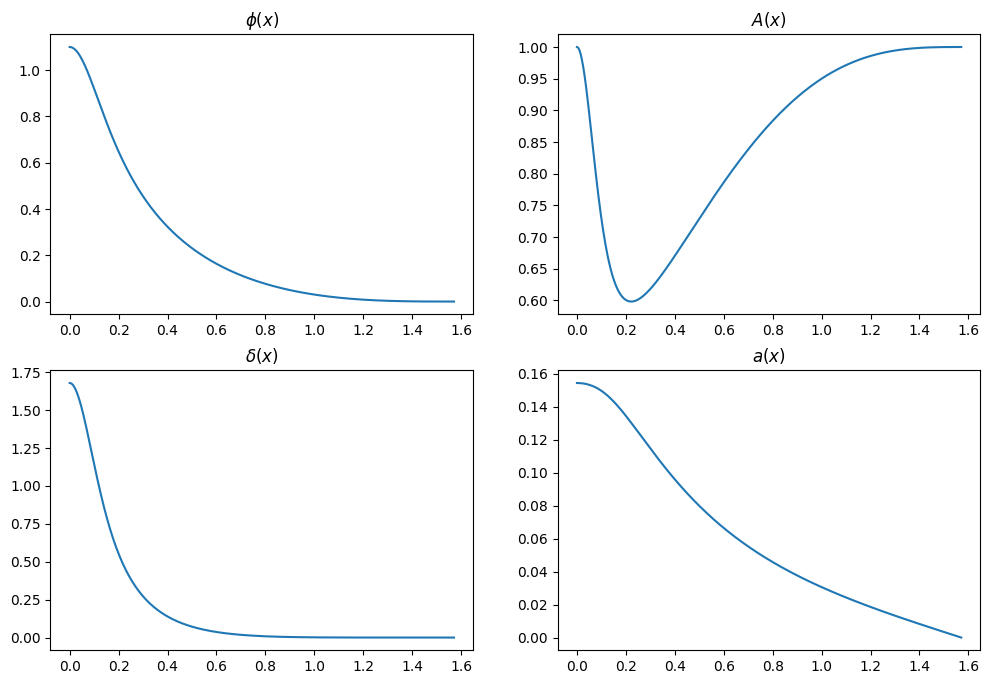

In [8]:
%matplotlib inline
solver.get_star_profile()
solver.plot_star_profile()

## Investigating families of solutions

In [9]:
class Tracer:
    def __init__(self, d=3, l=1.0, el=0.0, kappa=1.0, mass=0.0, **kwargs):
        self.kwargs = kwargs
        self.d = d
        self.l = l
        self.kappa = kappa
        self.el = el
        self.mass = mass

    def manual_trace(self, phi0_ranges, omega_ranges):
        self.phi0_values = np.empty(shape=0)
        self.omega_values = np.empty(shape=0)
        self.star_mass_values = np.empty(shape=0)
        self.star_charge_values = np.empty(shape=0)
        
        for phi0_range, omega_range in zip(phi0_ranges, omega_ranges):
            phi0_space = np.linspace(*phi0_range)
            omegas = []
            star_masses = []
            star_charges = []
            for phi0 in phi0_space:
                solver = Bose_Star_Solver(d=self.d, l=self.l, kappa=self.kappa, el=self.el, mass=self.mass, phi0=phi0, **self.kwargs)
                # print(phi0)
                with HidePrinting() as hp:
                    try:
                        solver.shoot_for_omega(omega_range=omega_range)
                    except RuntimeError:
                        hp.unblock()
                        print('phi0 explored', phi0)
                        return
                omegas.append(solver.omega)
                star_masses.append(solver.star_mass)
                star_charges.append(solver.star_charge)
            
            self.phi0_values = np.append(self.phi0_values, phi0_space)
            self.omega_values = np.append(self.omega_values, omegas)
            self.star_mass_values = np.append(self.star_mass_values, star_masses)
            self.star_charge_values = np.append(self.star_charge_values, star_charges)
            
    def auto_trace(self, phi0_range, omega_initial_range):
        self.phi0_values = np.linspace(*phi0_range)
        self.omega_values = []
        self.star_mass_values = []
        self.star_charge_values = []
        
        step_out = 0.2
        omega_range = copy.copy(omega_initial_range)
        
        for phi0 in self.phi0_values:
            solver = Bose_Star_Solver(d=self.d, l=self.l, kappa=self.kappa, el=self.el, mass=self.mass, phi0=phi0, **self.kwargs)
            # print(phi0, omega_range)
            with HidePrinting() as hp:
                try:
                    solver.shoot_for_omega(omega_range=omega_range)
                except RuntimeError:
                    hp.unblock()
                    print('phi0 explored', phi0)
                    return
                
            omega_reconstruct = np.exp(solver.delta0)*(solver.omega - self.el*solver.a0)
            omega_range = [(1.0 - step_out)*omega_reconstruct, (1.0 + step_out)*omega_reconstruct]

            self.omega_values.append(solver.omega)
            self.star_mass_values.append(solver.star_mass)
            self.star_charge_values.append(solver.star_charge)
            
    def plot_omega_curves(self, ax, **kwargs):
        ax.plot(self.phi0_values, self.omega_values, **kwargs)
        ax.set_xlabel('$\\phi_0$')
        ax.set_ylabel('$\\omega$')
        
    def plot_mass_curves(self, ax, **kwargs):
        ax.plot(self.phi0_values, self.star_mass_values, **kwargs)
        ax.set_xlabel('$\\phi_0$')
        ax.set_ylabel('$M$, star mass')
        
    def plot_charge_curves(self, ax, **kwargs):
        ax.plot(self.phi0_values, self.star_charge_values, **kwargs)
        ax.set_xlabel('$\\phi_0$')
        ax.set_ylabel('$Q/e$, star charge')

### Branch checker

Omega found by shooting 3.9818
Star mass is equal to 0.0052


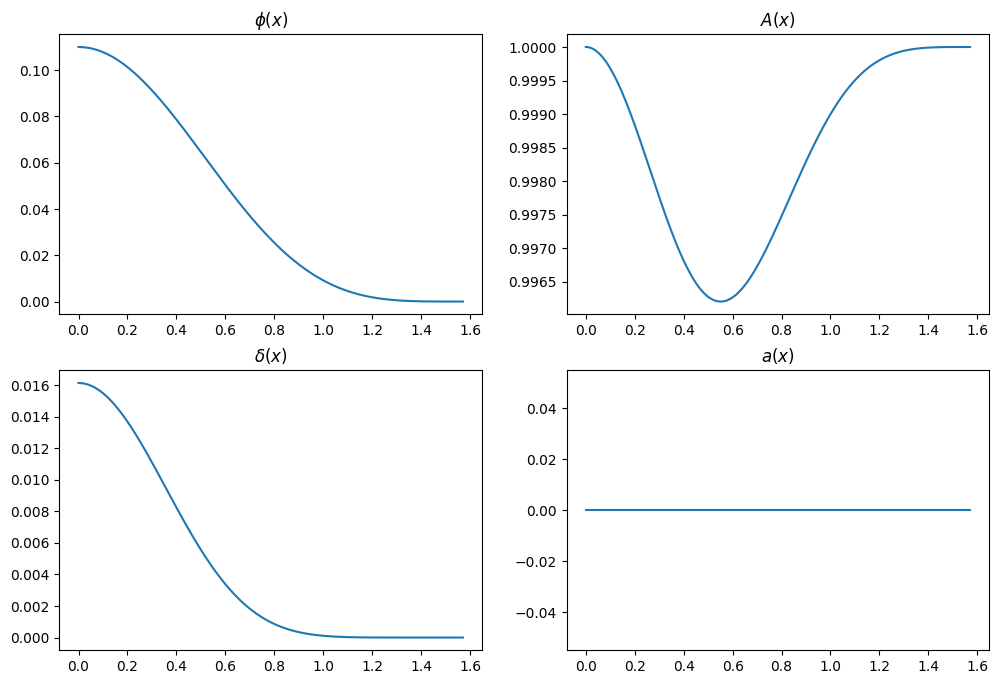

In [10]:
solver = Bose_Star_Solver(d=4, l=1.0, kappa=1.0, el = 0.0, mass=0.0, phi0=0.11)
solver.shoot_for_omega(omega_range=[3,5])
solver.get_star_profile()
solver.plot_star_profile()

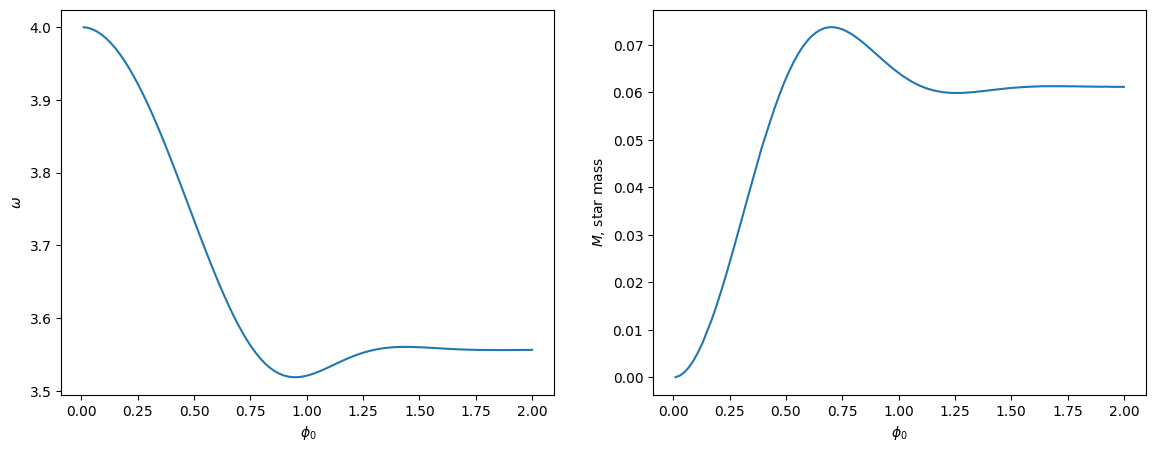

In [11]:
tracer = Tracer(d=4, l=1.0, el=1.0, kappa=1.0, mass=0.0, xrange=[0.0001, 1.3])
tracer.auto_trace((0.01, 2.0, 100), [3, 5])

fig = plt.figure(figsize=(14,5))

ax = fig.add_subplot(121)
tracer.plot_omega_curves(ax=ax, label='')

ax = fig.add_subplot(122)
tracer.plot_mass_curves(ax=ax, label='')

plt.show()

### Checking right boundary accuracy

In [12]:
tracer_zero = Tracer(d=3, l=1.0, el=1.5, kappa=1.0, mass=0.0, xrange=[0.0001, 1.4])
tracer_zero.auto_trace((0.01, 2.0, 100), [2, 4])

tracer_zero_alt = Tracer(d=3, l=1.0, el=1.5, kappa=1.0, mass=0.0, xrange=[0.0001, 1.35])
tracer_zero_alt.auto_trace((0.01, 2.0, 100), [2, 4])

In [13]:
print("Maximal deviation of omega: %.2e" % np.abs(np.array(tracer_zero.omega_values) - np.array(tracer_zero_alt.omega_values)).max())
print("Maximal deviation of mass: %.2e" % np.abs(np.array(tracer_zero.star_mass_values) - np.array(tracer_zero_alt.star_mass_values)).max())

Maximal deviation of omega: 5.28e-05
Maximal deviation of mass: 2.53e-04


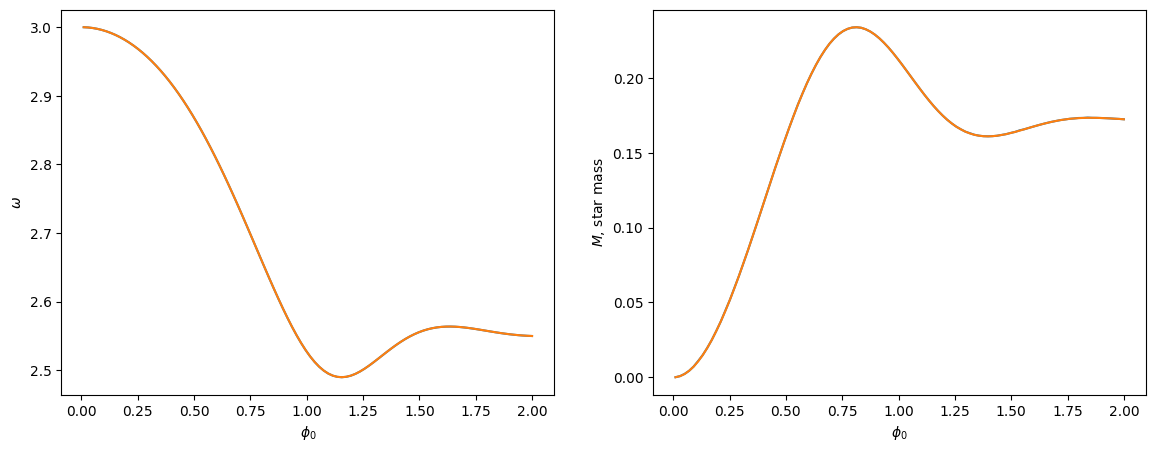

In [14]:
fig = plt.figure(figsize=(14,5))

ax = fig.add_subplot(121)
tracer_zero.plot_omega_curves(ax=ax, label='boundary at 1.4')
tracer_zero_alt.plot_omega_curves(ax=ax, label='boundary at 1.35')

ax = fig.add_subplot(122)
tracer_zero.plot_mass_curves(ax=ax, label='boundary at 1.4')
tracer_zero_alt.plot_mass_curves(ax=ax, label='boundary at 1.35')

plt.show()

### Looking at solutions with different scalar field masses

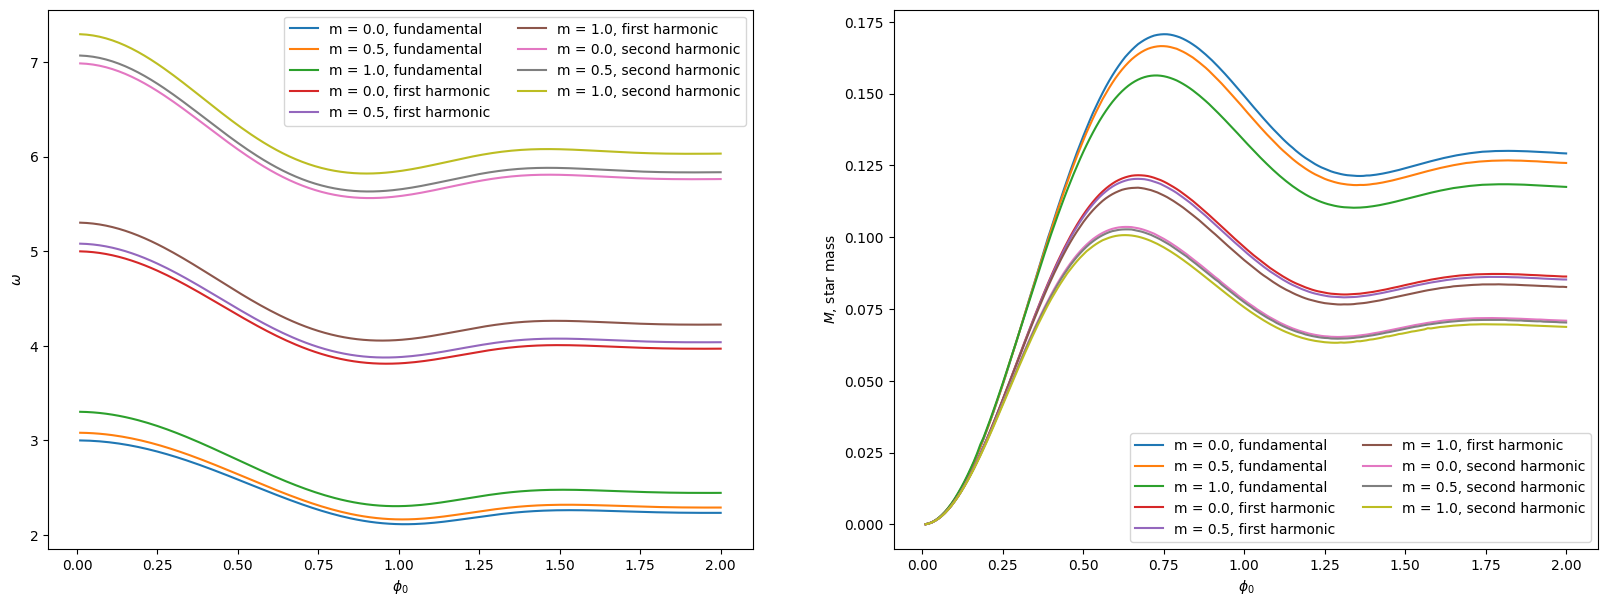

In [15]:
masses = [0.0, 0.5, 1.0]
zero_mode = []
first_harmonic = []
second_harmonic = []

for mass in masses:
    #Finding zero mode
    tracer = Tracer(d=3, l=1.0, el=0.0, kappa=1.0, mass=mass, xrange=[0.0001, 1.35])
    tracer.auto_trace((0.01, 2.0, 200), [2,4])
    zero_mode.append(tracer)
    
    #Finding first harmonic
    tracer = Tracer(d=3, l=1.0, el=0.0, kappa=1.0, mass=mass, xrange=[0.0001, 1.35])
    tracer.auto_trace((0.01, 2.0, 200), [4,6])
    first_harmonic.append(tracer)
    
    #Finding second harmonic
    tracer = Tracer(d=3, l=1.0, el=0.0, kappa=1.0, mass=mass, xrange=[0.0001, 1.35])
    tracer.auto_trace((0.01, 2.0, 200), [6,8])
    second_harmonic.append(tracer)
    
fig = plt.figure(figsize=(20,7))

ax = fig.add_subplot(121)
for mass, tracer in zip(masses, zero_mode):
    tracer.plot_omega_curves(ax=ax, label='m = %.1lf, fundamental' % mass)
for mass, tracer in zip(masses, first_harmonic):
    tracer.plot_omega_curves(ax=ax, label='m = %.1lf, first harmonic' % mass)
for mass, tracer in zip(masses, second_harmonic):
    tracer.plot_omega_curves(ax=ax, label='m = %.1lf, second harmonic' % mass)
ax.legend(loc='upper right', ncol=2)

ax = fig.add_subplot(122)
for mass, tracer in zip(masses, zero_mode):
    tracer.plot_mass_curves(ax=ax, label='m = %.1lf, fundamental' % mass)
for mass, tracer in zip(masses, first_harmonic):
    tracer.plot_mass_curves(ax=ax, label='m = %.1lf, first harmonic' % mass)
for mass, tracer in zip(masses, second_harmonic):
    tracer.plot_mass_curves(ax=ax, label='m = %.1lf, second harmonic' % mass)
ax.legend(ncol=2)

plt.savefig(plots_directory + '/mass_curves.png', dpi=300)
plt.show()

### Looking at solutions with different charges

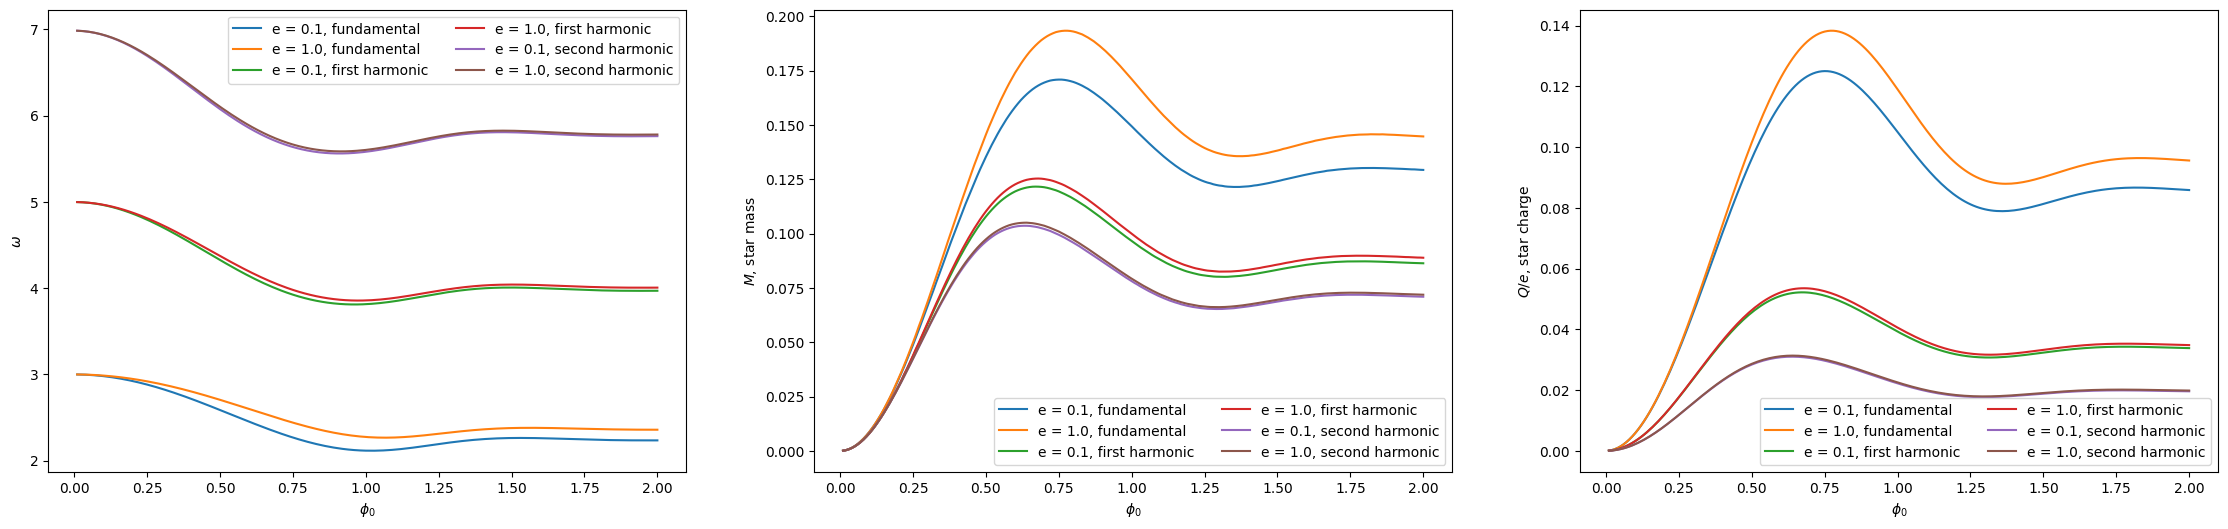

In [16]:
charges = [0.1, 1.0]
zero_mode = []
first_harmonic = []
second_harmonic = []

for charge in charges:
    #Finding zero mode
    tracer = Tracer(d=3, l=1.0, el=charge, kappa=1.0, mass=0.0, xrange=[0.0001, 1.35])
    tracer.auto_trace((0.01, 2.0, 200), [2,4])
    zero_mode.append(tracer)
    
    #Finding first harmonic
    tracer = Tracer(d=3, l=1.0, el=charge, kappa=1.0, mass=0.0, xrange=[0.0001, 1.35])
    tracer.auto_trace((0.01, 2.0, 200), [4,6])
    first_harmonic.append(tracer)
    
    #Finding second harmonic
    tracer = Tracer(d=3, l=1.0, el=charge, kappa=1.0, mass=0.0, xrange=[0.0001, 1.35])
    tracer.auto_trace((0.01, 2.0, 200), [6,8])
    second_harmonic.append(tracer)
    
fig = plt.figure(figsize=(28,6))

ax = fig.add_subplot(131)
for charge, tracer in zip(charges, zero_mode):
    tracer.plot_omega_curves(ax=ax, label='e = %.1lf, fundamental' % charge)
for charge, tracer in zip(charges, first_harmonic):
    tracer.plot_omega_curves(ax=ax, label='e = %.1lf, first harmonic' % charge)
for charge, tracer in zip(charges, second_harmonic):
    tracer.plot_omega_curves(ax=ax, label='e = %.1lf, second harmonic' % charge)
ax.legend(loc='upper right', ncol=2)

ax = fig.add_subplot(132)
for charge, tracer in zip(charges, zero_mode):
    tracer.plot_mass_curves(ax=ax, label='e = %.1lf, fundamental' % charge)
for charge, tracer in zip(charges, first_harmonic):
    tracer.plot_mass_curves(ax=ax, label='e = %.1lf, first harmonic' % charge)
for charge, tracer in zip(charges, second_harmonic):
    tracer.plot_mass_curves(ax=ax, label='e = %.1lf, second harmonic' % charge)
ax.legend(ncol=2)

ax = fig.add_subplot(133)
for charge, tracer in zip(charges, zero_mode):
    tracer.plot_charge_curves(ax=ax, label='e = %.1lf, fundamental' % charge)
for charge, tracer in zip(charges, first_harmonic):
    tracer.plot_charge_curves(ax=ax, label='e = %.1lf, first harmonic' % charge)
for charge, tracer in zip(charges, second_harmonic):
    tracer.plot_charge_curves(ax=ax, label='e = %.1lf, second harmonic' % charge)
ax.legend(ncol=2)

plt.savefig(plots_directory + '/el_constant_curves.png', dpi=300)
plt.show()

### Looking at solutions with different dimensions

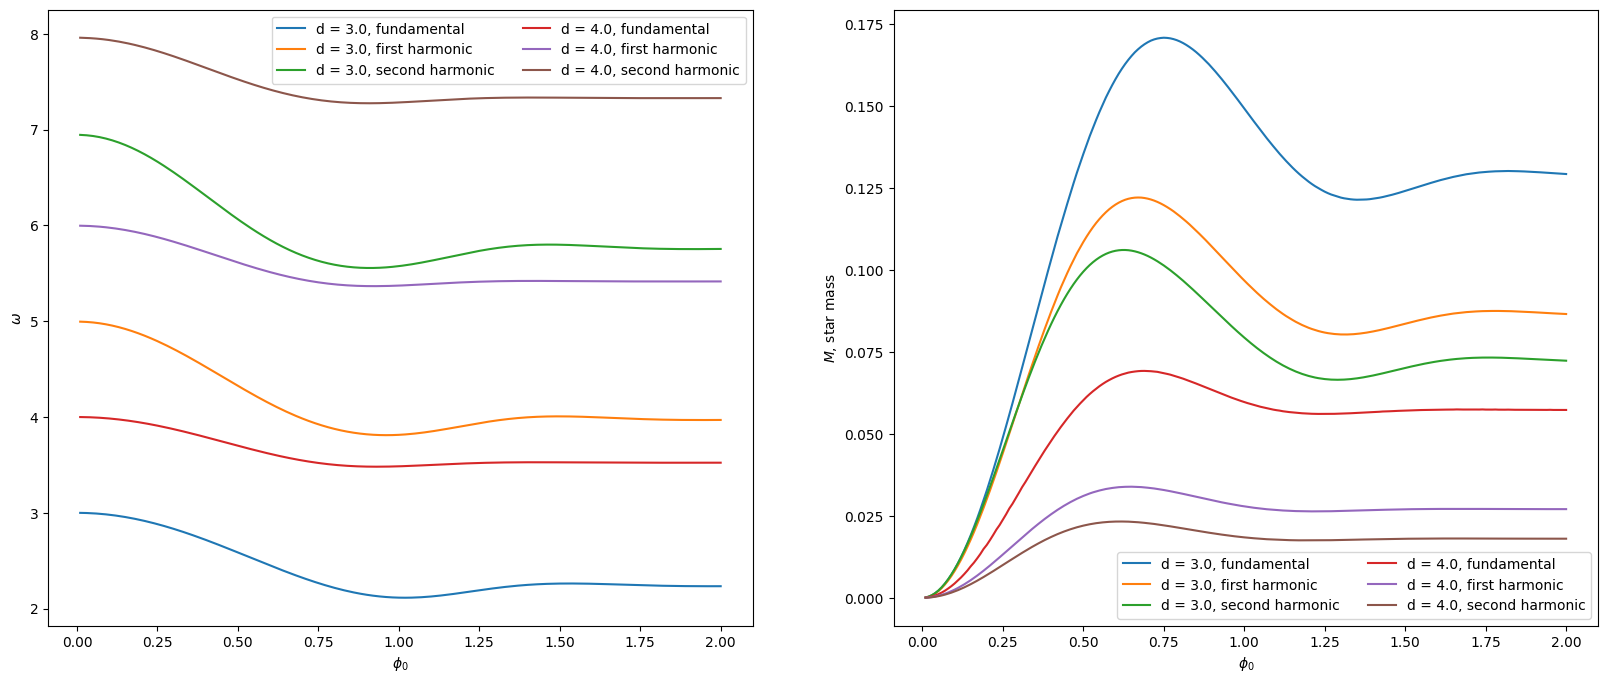

In [17]:
dimensions = [3,4]
zero_mode = []
first_harmonic = []
second_harmonic = []

for dim in dimensions:
    #Finding zero mode
    tracer = Tracer(d=dim, l=1.0, el=0.0, kappa=1.0, mass=0.0, xrange=[0.0001, 1.3])
    tracer.auto_trace((0.01, 2.0, 200), [dim-1,dim+1])
    zero_mode.append(tracer)
    
    #Finding first harmonic
    tracer = Tracer(d=dim, l=1.0, el=0.0, kappa=1.0, mass=0.0, xrange=[0.0001, 1.3])
    tracer.auto_trace((0.01, 2.0, 200), [dim+1,dim+3])
    first_harmonic.append(tracer)
    
    #Finding second harmonic
    tracer = Tracer(d=dim, l=1.0, el=0.0, kappa=1.0, mass=0.0, xrange=[0.0001, 1.3])
    tracer.auto_trace((0.01, 2.0, 200), [dim+3,dim+5])
    second_harmonic.append(tracer)
    
fig = plt.figure(figsize=(20,8))

ax = fig.add_subplot(121)
for dim, tracer_zero, tracer_one, tracer_two in zip(dimensions, zero_mode, first_harmonic, second_harmonic):
    tracer_zero.plot_omega_curves(ax=ax, label='d = %.1lf, fundamental' % dim)
    tracer_one.plot_omega_curves(ax=ax, label='d = %.1lf, first harmonic' % dim)
    tracer_two.plot_omega_curves(ax=ax, label='d = %.1lf, second harmonic' % dim)
ax.legend(loc='upper right', ncol=2)

ax = fig.add_subplot(122)
for dim, tracer_zero, tracer_one, tracer_two in zip(dimensions, zero_mode, first_harmonic, second_harmonic):
    tracer_zero.plot_mass_curves(ax=ax, label='d = %.1lf, fundamental' % dim)
    tracer_one.plot_mass_curves(ax=ax, label='d = %.1lf, first harmonic' % dim)
    tracer_two.plot_mass_curves(ax=ax, label='d = %.1lf, second harmonic' % dim)
ax.legend(ncol=2)

plt.savefig(plots_directory + '/dim_curves.png', dpi=300)
plt.show()

## Solution space exploration

The explorer class computes the difference between the scalar field derivatives found by RK integration and from the asymptotic for a fixed value of central scalar field. This difference should be matched to zero by shooting. It then finds all the intervals which have zeros. It then can use shooting to find a solution there and characterize it.

In [18]:
class Explorer:
    def __init__(self, d=3, l=1.0, el=0.0, kappa=1.0, mass=0.0, phi0=1.0):
        self.d = d
        self.l = l
        self.kappa = kappa
        self.el = el
        self.mass = mass
        self.phi0 = phi0
    
    def scan_omega_range(self, omega_st, omega_end, npoints=101, **kwargs):
        if 'ax' in kwargs:
            ax = kwargs.pop('ax')
        if 'xrange' in kwargs:
            xrange = kwargs.pop('xrange')
        else:
            xrange = [0.0001, 1.4]
        if(len(kwargs) > 0):
            raise TypeError(list(kwargs.keys())[0] + ' is an invalid keyword argument')
            
        self.omega_range = np.linspace(omega_st, omega_end, npoints)
        self.dy_values = []
        
        solver_manual = Bose_Star_Manual(d=self.d, l=self.l, kappa=self.kappa, el=self.el, mass=self.mass, phi0=self.phi0, xrange=xrange)
        
        for omega in self.omega_range:
            try:
                val = solver_manual.shoot_dy(omega)
                self.dy_values.append(val)
            except RuntimeError:
                self.dy_values.append(np.nan)
                continue
                # print('omega explored', omega)
        
        self.dy_values = np.array(self.dy_values)
        mask = self.dy_values[:-1]*self.dy_values[1:] < 0
        self.zero_intervals = np.c_[self.omega_range[:-1][mask],self.omega_range[1:][mask]]
        print('Number of potential shooting solutions found', self.zero_intervals.shape[0])
        
        for inter in self.zero_intervals:
            print('A zero found in the interval', inter)
        
        if 'ax' in locals():
            ax.plot(expl.omega_range, expl.dy_values)
        
    def explore_zeros_by_shooting(self, **kwargs):
        if 'xrange' in kwargs:
            xrange = kwargs.pop('xrange')
        else:
            xrange = [0.0001, 1.4]
        if(len(kwargs) > 0):
            raise TypeError(list(kwargs.keys())[0] + ' is an invalid keyword argument')
            
        solver = Bose_Star_Solver(d=self.d, l=self.l, kappa=self.kappa, el=self.el, mass=self.mass, phi0=self.phi0, xrange=xrange)
        self.solutions = []
        
        for omega_range in self.zero_intervals:
            with HidePrinting() as hp:
                try:
                    solver.shoot_for_omega(omega_range=omega_range)
                except RuntimeError:
                    hp.unblock()
                    print('phi0 explored', phi0)
                    continue
            
            solver.get_star_profile()
            phi_field = solver.fields[:,2]
            np.count_nonzero(phi_field[1:]*phi_field[:-1] < 0)
            
            self.solutions.append([np.count_nonzero(phi_field[1:]*phi_field[:-1] < 0),
                                 solver.omega,
                                 solver.star_mass,
                                 solver.star_charge])
        
        print('%d stars confirmed:' % len(self.solutions))
        for solution in self.solutions:
            print('A star with %d nodes, omega %.2lf, mass %.2lf and charge %.2lf' % tuple(solution))

### Test case

Number of potential shooting solutions found 2
A zero found in the interval [8.6 8.8]
A zero found in the interval [17.4 17.6]


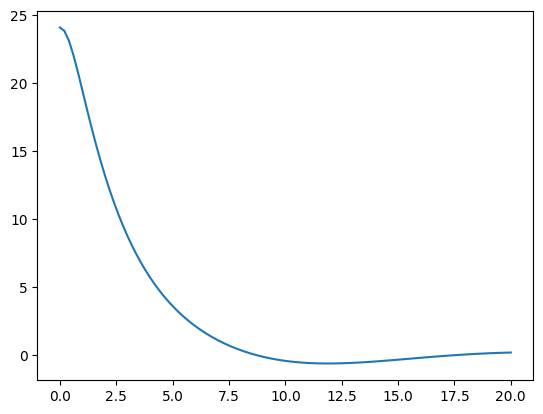

In [19]:
expl = Explorer(d=3, l=1.0, kappa=1.0, el=0.0, mass=0.0, phi0=1.0)

ax = plt.subplot()
expl.scan_omega_range(0.0, 20.0, ax=ax)
plt.show()

In [20]:
expl.explore_zeros_by_shooting()

2 stars confirmed:
A star with 0 nodes, omega 2.11, mass 0.15 and charge 0.00
A star with 1 nodes, omega 3.81, mass 0.10 and charge 0.00


## Large gauge coupling limit

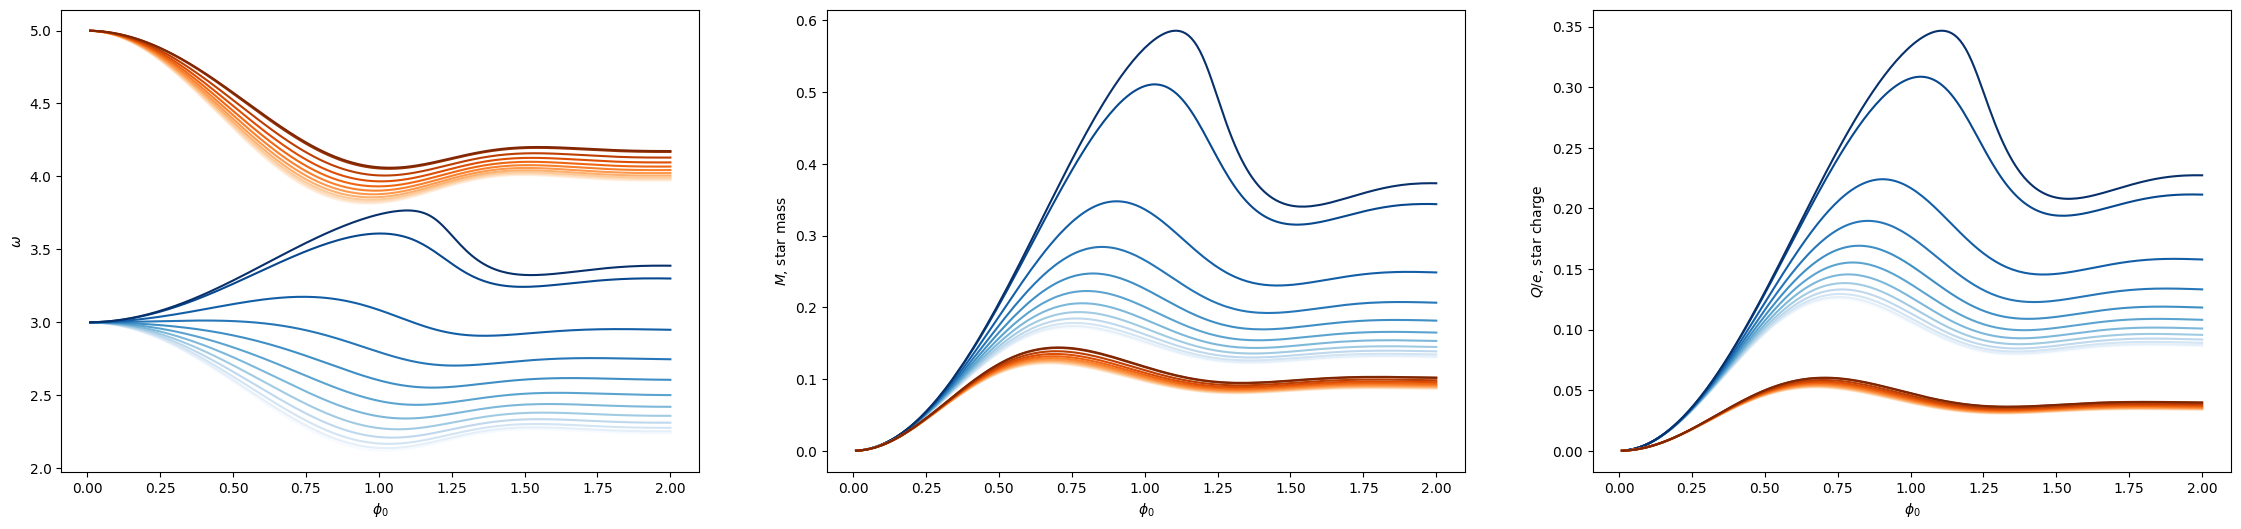

In [21]:
charges = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.23]
# charges = [0.2, 0.6, 1.0, 1.4, 1.8, 2.2, 2.23]
zero_mode = []
first_harmonic = []
second_harmonic = []

for charge in charges:
    #Finding zero mode
    tracer = Tracer(d=3, l=1.0, el=charge, kappa=1.0, mass=0.0, xrange=[0.0001, 1.35])
    tracer.auto_trace((0.01, 2.0, 200), [2,4])
    zero_mode.append(tracer)
    
    #Finding first harmonic
    tracer = Tracer(d=3, l=1.0, el=charge, kappa=1.0, mass=0.0, xrange=[0.0001, 1.35])
    tracer.auto_trace((0.01, 2.0, 200), [4,6])
    first_harmonic.append(tracer)
    
    # #Finding second harmonic
    # tracer = Tracer(d=3, l=1.0, el=charge, kappa=1.0, mass=0.0, xrange=[0.0001, 1.35])
    # tracer.auto_trace((0.01, 2.0, 200), [6,8])
    # second_harmonic.append(tracer)

c = np.arange(1, len(charges) + 1)
norm = mpl.colors.Normalize(vmin=c.min(), vmax=c.max())
# Color map for the fundamental mode
cmap_fund = mpl.cm.ScalarMappable(norm=norm, cmap=mpl.cm.Blues)
cmap_fund.set_array([])
# Color map for the first mode
cmap_first = mpl.cm.ScalarMappable(norm=norm, cmap=mpl.cm.Oranges)
cmap_first.set_array([])
    
fig = plt.figure(figsize=(28,6))

ax = fig.add_subplot(131)
for i, (charge, tracer) in enumerate(zip(charges, zero_mode)):
    tracer.plot_omega_curves(ax=ax, label='e = %.1lf, fundamental' % charge, c=cmap_fund.to_rgba(i+1))
for i, (charge, tracer) in enumerate(zip(charges, first_harmonic)):
    tracer.plot_omega_curves(ax=ax, label='e = %.1lf, first harmonic' % charge, c=cmap_first.to_rgba(i+1))
# for charge, tracer in zip(charges, second_harmonic):
#     tracer.plot_omega_curves(ax=ax, label='e = %.1lf, second harmonic' % charge)

ax = fig.add_subplot(132)
for i, (charge, tracer) in enumerate(zip(charges, zero_mode)):
    tracer.plot_mass_curves(ax=ax, label='e = %.1lf, fundamental' % charge, c=cmap_fund.to_rgba(i+1))
for i, (charge, tracer) in enumerate(zip(charges, first_harmonic)):
    tracer.plot_mass_curves(ax=ax, label='e = %.1lf, first harmonic' % charge, c=cmap_first.to_rgba(i+1))
# for charge, tracer in zip(charges, second_harmonic):
#     tracer.plot_mass_curves(ax=ax, label='e = %.1lf, second harmonic' % charge)

ax = fig.add_subplot(133)
for i, (charge, tracer) in enumerate(zip(charges, zero_mode)):
    tracer.plot_charge_curves(ax=ax, label='e = %.1lf, fundamental' % charge, c=cmap_fund.to_rgba(i+1))
for i, (charge, tracer) in enumerate(zip(charges, first_harmonic)):
    tracer.plot_charge_curves(ax=ax, label='e = %.1lf, first harmonic' % charge, c=cmap_first.to_rgba(i+1))
# for charge, tracer in zip(charges, second_harmonic):
#     tracer.plot_charge_curves(ax=ax, label='e = %.1lf, second harmonic' % charge)

# ax = fig.add_subplot(224)
# for charge, tracer in zip(charges, zero_mode):
#     ax.plot(tracer.phi0_values, np.array(tracer.star_charge_values)/np.array(tracer.star_mass_values), label='e = %.1lf, fundamental' % charge)
#     ax.set_xlabel('$\\phi_0$')
#     ax.set_ylabel('$Q/(e M)$, star charge')

# for charge, tracer in zip(charges, first_harmonic):
#     ax.plot(tracer.phi0_values, np.array(tracer.star_charge_values)/np.array(tracer.star_mass_values), label='e = %.1lf, first' % charge)
#     ax.set_xlabel('$\\phi_0$')
#     ax.set_ylabel('$Q/(e M)$, star charge')

# for charge, tracer in zip(charges, second_harmonic):
#     ax.plot(tracer.phi0_values, np.array(tracer.star_charge_values)/np.array(tracer.star_mass_values), label='e = %.1lf, second' % charge)
#     ax.set_xlabel('$\\phi_0$')
#     ax.set_ylabel('$Q/(e M)$, star charge')

plt.savefig(plots_directory + '/omega_phenomenon.png', dpi=300)
plt.savefig
plt.show()

We see that as the gauge coupling increases the frequency curve for the fundamental mode grows closer to the frequency curve of the first mode. We investigate this phenomenon further

### The case before the frequency curves overlap

Even when two modes are separated there is secretly another family of soluions. This family also has no nodes (scalar field never crosses zero), we map out these two families.

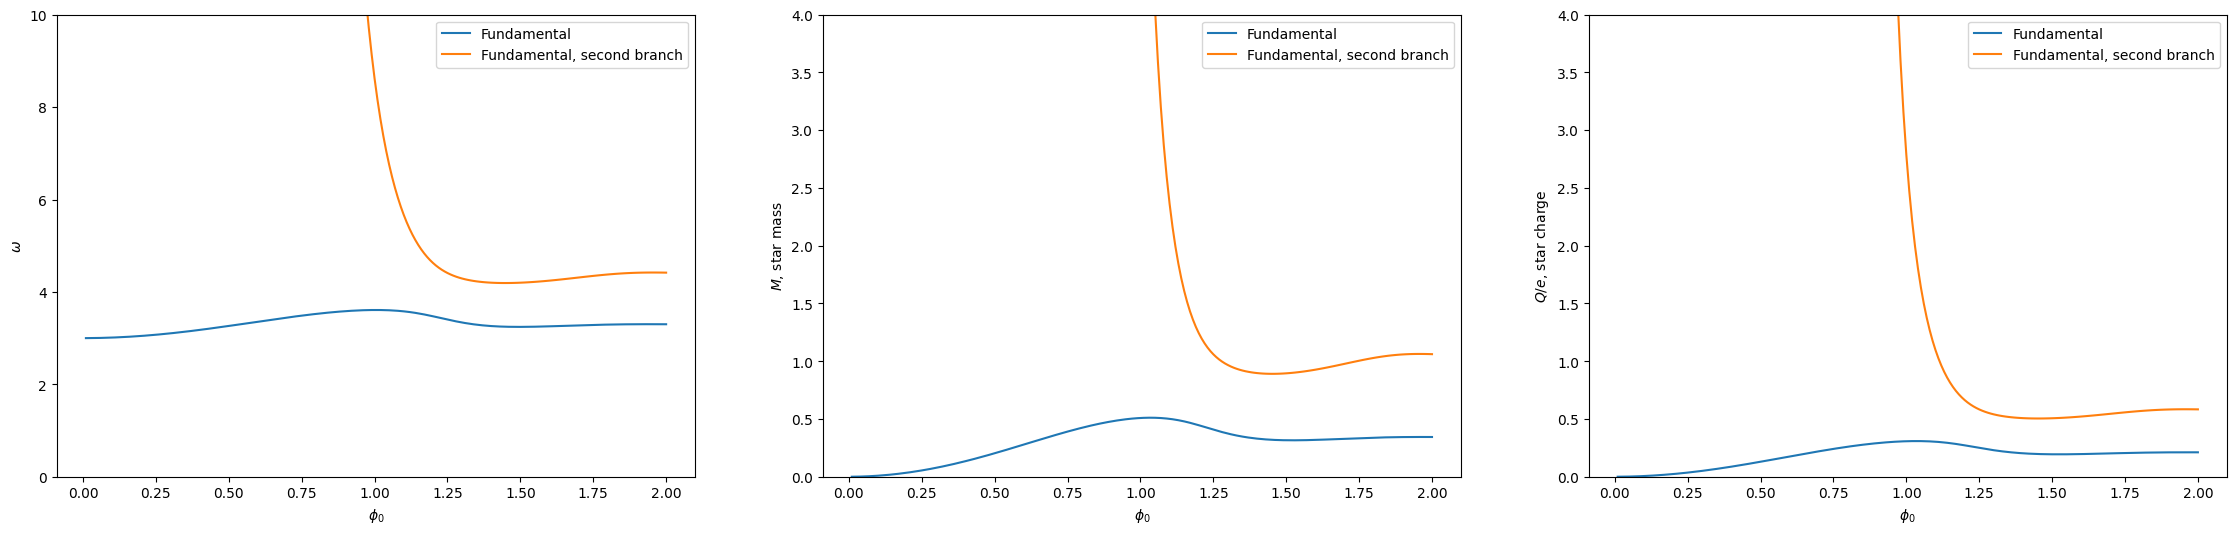

In [22]:
tracer_zero = Tracer(d=3, l=1.0, el=2.2, kappa=1.0, mass=0.0, xrange=[0.0001, 1.35])
tracer_zero.auto_trace((0.01, 2.0, 200), [2,4])

phi0_ranges = [(0.95, 1.0, 6), (1.01, 1.09, 9), (1.1, 1.19, 10), (1.2, 1.29, 10), (1.3, 1.39, 10), (1.4, 1.49, 10),
               (1.5, 1.59, 10), (1.6, 1.69, 10), (1.7, 1.79, 10), (1.8, 1.89, 10), (1.9, 2.0, 11)]
omega_ranges = [(0.6, 1.5), (1.2, 2.5), (2, 4), (3, 6), (5, 10), (6, 10), (8, 12), (11, 20), (15, 25), (20, 35), (30, 50)]

tracer_zero_b2 = Tracer(d=3, l=1.0, el=2.2, kappa=1.0, mass=0.0, xrange=[0.001, 1.4])
tracer_zero_b2.manual_trace(phi0_ranges, omega_ranges)

fig = plt.figure(figsize=(28,6))

ax = fig.add_subplot(131)
tracer_zero.plot_omega_curves(ax=ax, label='Fundamental')
tracer_zero_b2.plot_omega_curves(ax=ax, label='Fundamental, second branch')
# tracer_one.plot_omega_curves(ax=ax, label='First harmonic')
ax.set_ylim(0,10.0)
ax.legend()

ax = fig.add_subplot(132)
tracer_zero.plot_mass_curves(ax=ax, label='Fundamental')
tracer_zero_b2.plot_mass_curves(ax=ax, label='Fundamental, second branch')
ax.set_ylim(0,4.0)
ax.legend()

ax = fig.add_subplot(133)
tracer_zero.plot_charge_curves(ax=ax, label='Fundamental')
tracer_zero_b2.plot_charge_curves(ax=ax, label='Fundamental, second branch')
ax.set_ylim(0,4.0)
ax.legend()

plt.savefig(plots_directory + '/precrossing.png', dpi=300)
plt.show()

The second family has no zero scalar field limit. We give two characteristic representatives from these families.

Number of potential shooting solutions found 2
A zero found in the interval [1.18 1.27]
A zero found in the interval [4.69 4.78]


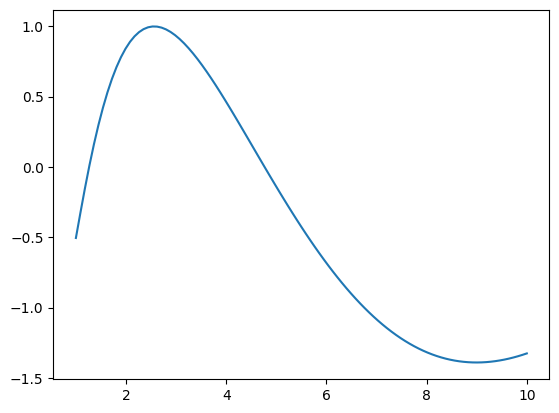

2 stars confirmed:
A star with 0 nodes, omega 8.71, mass 8.74 and charge 2.85
A star with 0 nodes, omega 3.61, mass 0.51 and charge 0.31


In [23]:
expl = Explorer(d=3, l=1.0, kappa=1.0, el=2.2, mass=0.0, phi0=1)

ax = plt.subplot()
expl.scan_omega_range(1.0, 10.0, ax=ax, xrange=[0.001, 1.5])
plt.show()

expl.explore_zeros_by_shooting(xrange=[0.001, 1.5])

A regular solution that can continuously be matched to $\phi \to 0$ solution with unperturbed AdS geometry.

Omega found by shooting 3.6080
Star mass is equal to 0.5079
Star charge is equal to 0.3069


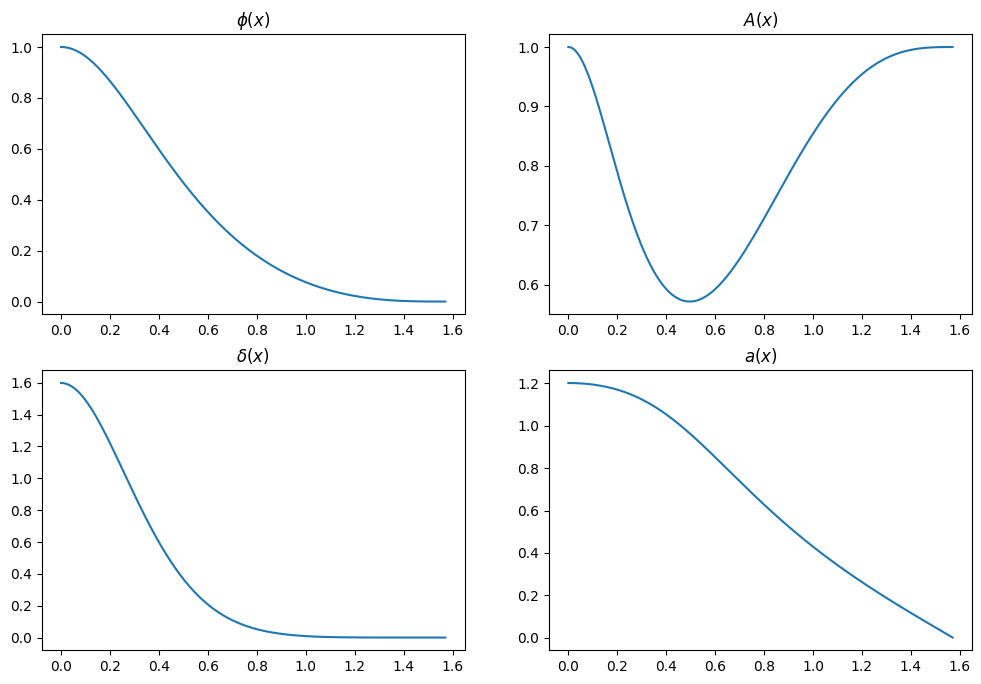

In [24]:
solver = Bose_Star_Solver(d=3, l=1.0, kappa=1.0, el=2.2, mass=0.0, phi0=1.0, xrange=[0.001, 1.4])
solver.shoot_for_omega(omega_range=[4,5])
solver.get_star_profile()
solver.plot_star_profile()

And an additional solution from a family with to unperturbed AdS limit and unbounded mass

Omega found by shooting 8.7082
Star mass is equal to 8.7413
Star charge is equal to 2.8453


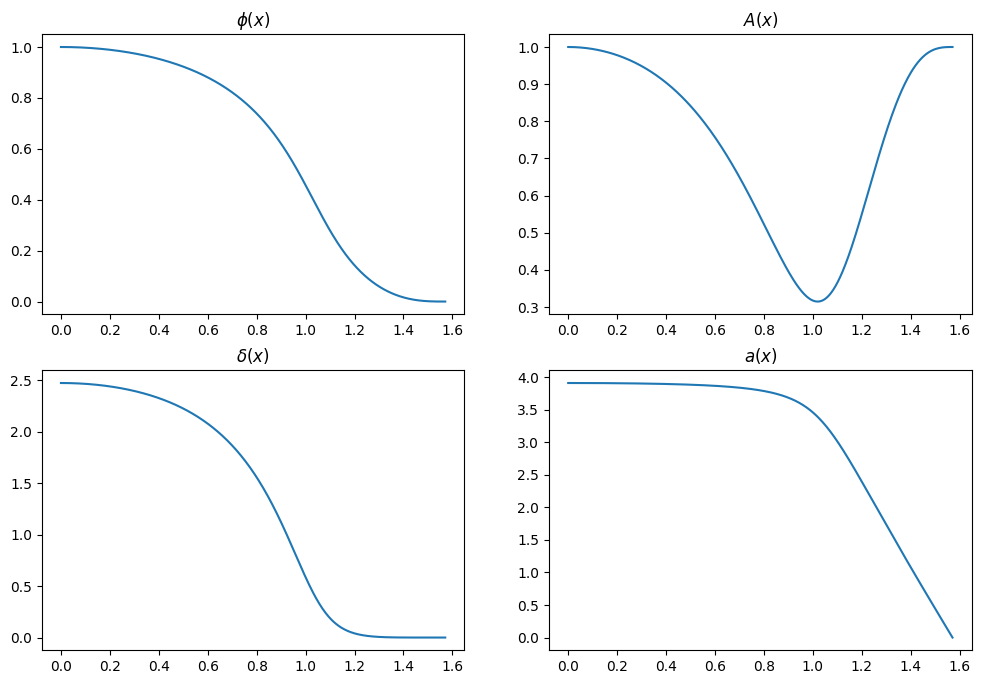

In [25]:
solver = Bose_Star_Solver(d=3, l=1.0, kappa=1.0, el=2.2, mass=0.0, phi0=1.0, xrange=[0.001, 1.5])
solver.shoot_for_omega(omega_range=[1,2])
solver.get_star_profile()
solver.plot_star_profile()

### The case after the frequency curves overlap

After the frequency curves overlap the two cross overlap as well and the picture changes dramatically

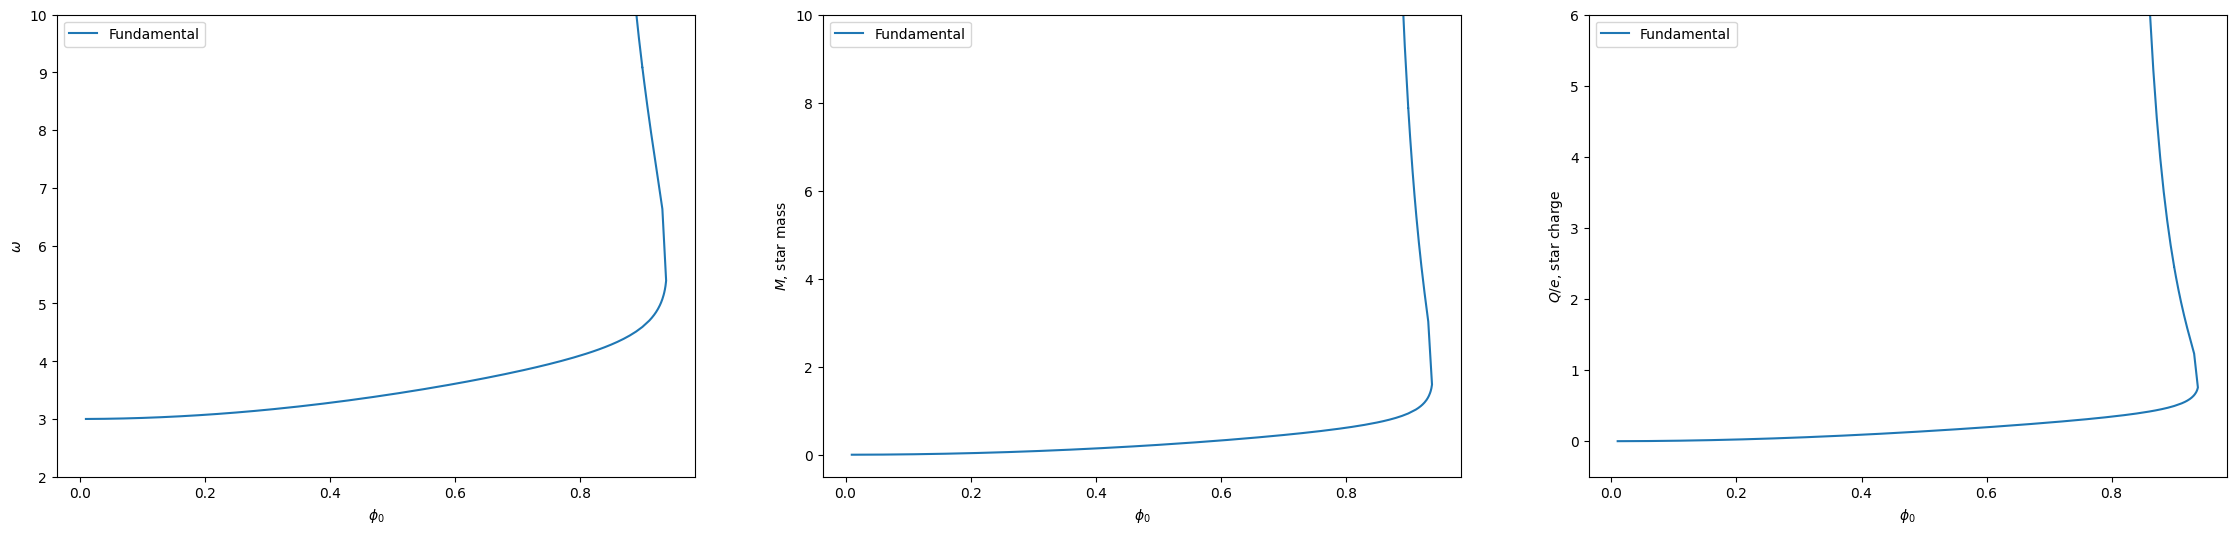

In [26]:
phi0_ranges = [(0.01, 0.9, 90), (0.91,0.938, 29)]
omega_ranges = [(2,4), (2.5,4)]

tracer_zero = Tracer(d=3, l=1.0, el=2.4, kappa=1.0, mass=0.0, xrange=[0.0001, 1.35])
tracer_zero.manual_trace(phi0_ranges, omega_ranges)

phi0_ranges = [(0.85, 0.9, 10), (0.9, 0.932, 33)]
omega_ranges = [(0.5,2), (1,2.81)]

tracer_zero_b2 = Tracer(d=3, l=1.0, el=2.4, kappa=1.0, mass=0.0, xrange=[0.0001, 1.5])
tracer_zero_b2.manual_trace(phi0_ranges, omega_ranges)

fig = plt.figure(figsize=(28,6))

ax = fig.add_subplot(131)
ax.plot(np.r_[tracer_zero.phi0_values,tracer_zero_b2.phi0_values[::-1]],
        np.r_[tracer_zero.omega_values,tracer_zero_b2.omega_values[::-1]], label='Fundamental')
ax.set_xlabel('$\\phi_0$')
ax.set_ylabel('$\\omega$')
ax.set_ylim(2,10)
ax.legend()

ax = fig.add_subplot(132)
ax.plot(np.r_[tracer_zero.phi0_values,tracer_zero_b2.phi0_values[::-1]],
        np.r_[tracer_zero.star_mass_values,tracer_zero_b2.star_mass_values[::-1]], label='Fundamental')
ax.set_xlabel('$\\phi_0$')
ax.set_ylabel('$M$, star mass')
ax.set_ylim(-0.5,10)
ax.legend()

ax = fig.add_subplot(133)
ax.plot(np.r_[tracer_zero.phi0_values,tracer_zero_b2.phi0_values[::-1]],
        np.r_[tracer_zero.star_charge_values,tracer_zero_b2.star_charge_values[::-1]], label='Fundamental')
ax.set_xlabel('$\\phi_0$')
ax.set_ylabel('$Q/e$, star charge')
ax.set_ylim(-0.5,6)
ax.legend()

plt.savefig(plots_directory + '/postcrossing.png', dpi=300)
plt.show()

There is also a second branch lying to the right of the fundamental branch, as opposed to the precrossing case this branch actually has one node. It is a bit annoying to track through, so we are not giving it here.

We provide two examples of stars lying on the fundamental branch below

Number of potential shooting solutions found 2
A zero found in the interval [1.22  1.265]
A zero found in the interval [3.11  3.155]


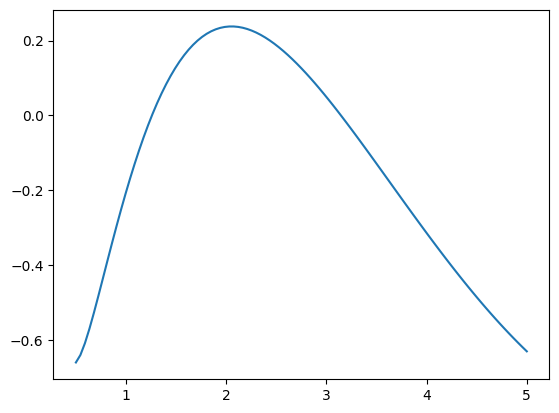

2 stars confirmed:
A star with 0 nodes, omega 9.05, mass 7.80 and charge 2.44
A star with 0 nodes, omega 4.58, mass 0.93 and charge 0.49


In [27]:
expl = Explorer(d=3, l=1.0, kappa=1.0, el=2.4, mass=0.0, phi0=0.9)

ax = plt.subplot()
expl.scan_omega_range(0.5, 5.0, ax=ax, xrange=[0.001, 1.45])
plt.show()

expl.explore_zeros_by_shooting(xrange=[0.001, 1.45])

We first find the star lying on the lower part of the curve

Omega found by shooting 4.5867
Star mass is equal to 0.9315
Star charge is equal to 0.4926


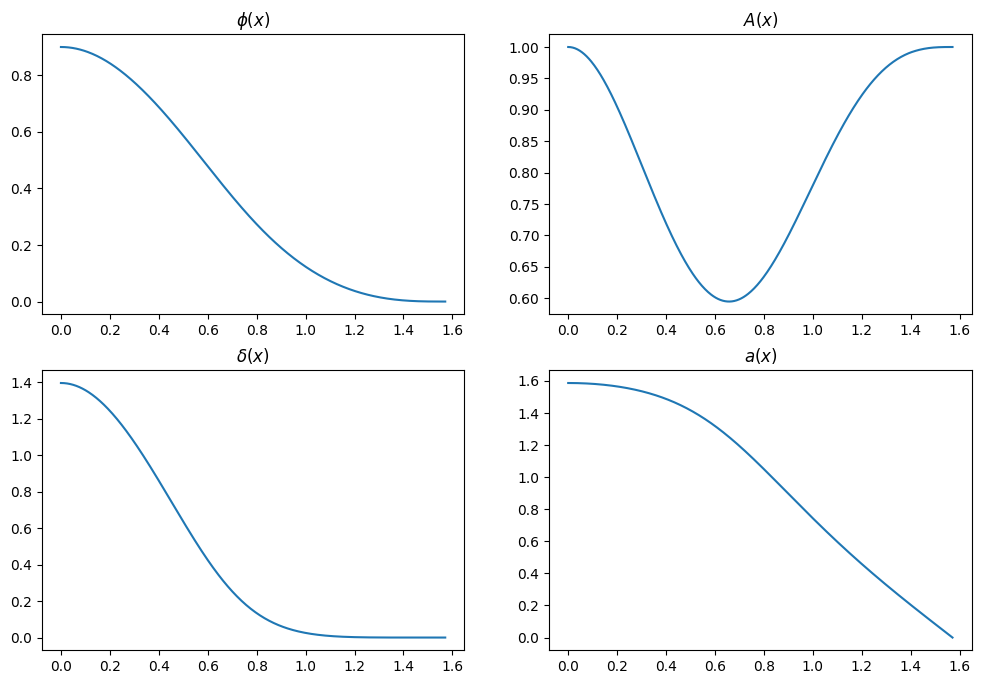

In [28]:
solver = Bose_Star_Solver(d=3, l=1.0, kappa=1.0, el=2.4, mass=0.0, phi0=0.9, xrange=[0.001, 1.4])
solver.shoot_for_omega(omega_range=[3,4])
solver.get_star_profile()
solver.plot_star_profile()

We then find the star lying on the upper part of the curve

Omega found by shooting 9.0874
Star mass is equal to 7.8769
Star charge is equal to 2.4554


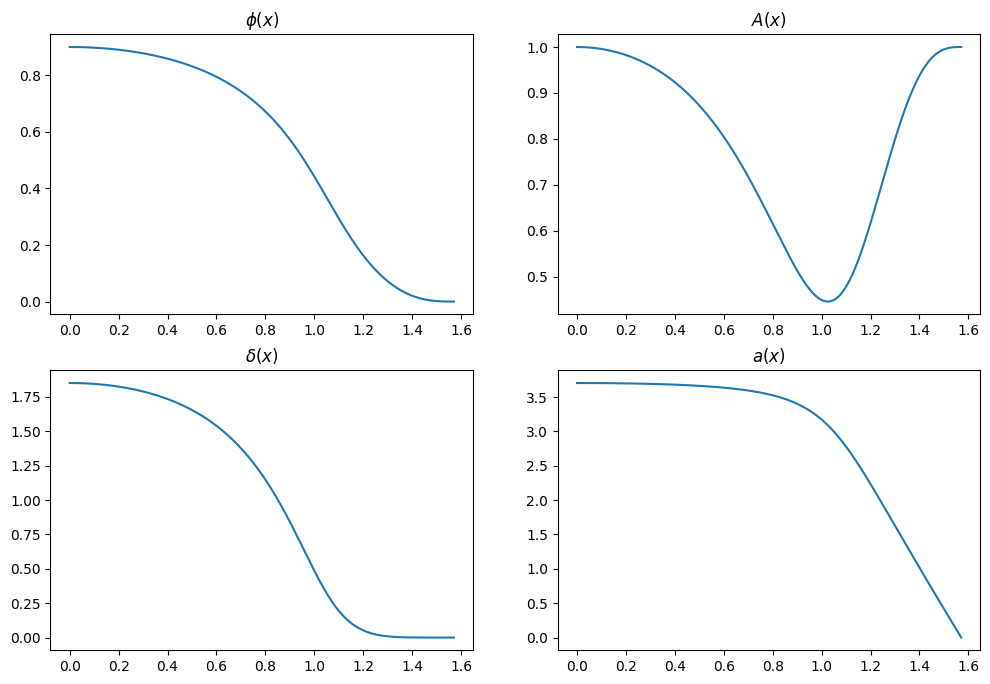

In [29]:
solver = Bose_Star_Solver(d=3, l=1.0, kappa=1.0, el=2.4, mass=0.0, phi0=0.9, xrange=[0.001, 1.5])
solver.shoot_for_omega(omega_range=[1,2])
solver.get_star_profile()
solver.plot_star_profile()

## Comparing with exact solution in the absence of gravity

In [30]:
from scipy.special import jacobi

The exact solutions for the scalar field in the absence of gravity is given by the formula
$$
\phi_j(x) = C (\cos x)^{(d + \sqrt{d^2 + 4 l^2 m^2})/2} P^{d/2 - 1, \sqrt{d^2 + 4 l^2 m^2}/2}_j(\cos 2x),
$$
and have the frequency
$$
\omega_j = \frac{1}{2}(d + \sqrt{d^2 + 4 l^2 m^2}) + 2j.
$$

In [31]:
class Phi_Exact:
    def __init__(self, d, l, m):
        self.d_2 = d/2.0
        self.l = l
        self.m = m
        self.alpha = self.d_2 - 1.0
        self.beta = 0.5*np.sqrt(d**2 + (2*m*l)**2)
    def omega(self, j):
        return self.d_2 + self.beta + 2*j
    def __call__(self, j, xrange):
        jacobi_j = jacobi(j, self.alpha, self.beta)
        norm = jacobi_j(1.0)
        return np.cos(xrange)**(self.d_2 + self.beta)*jacobi_j(np.cos(2*xrange))/norm

### $d = 2$

Omega found by shooting 2.1180
Exact omega 2.118033988749895
Maximal difference between numeric and exact solutions 3.79e-07


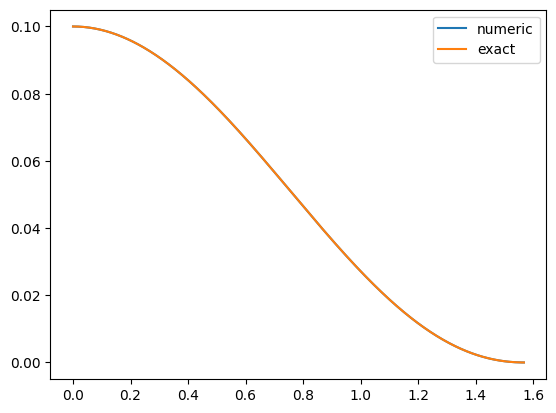

In [32]:
d = 2
l = 1
m = 0.5
solver = Bose_Star_Solver(d=d, l=l, kappa=0.0, el=0.0, mass=m, phi0=0.1)
phi_exact = Phi_Exact(d, l, m)

solver.shoot_for_omega(omega_range=[2, 3])
print("Exact omega", phi_exact.omega(0))

solver.get_star_profile()
phi_func = 0.1*phi_exact(0, solver.coords[:-1])
print("Maximal difference between numeric and exact solutions %.2e" % np.abs(phi_func - solver.fields[:-1,2]).max())

plt.plot(solver.coords[:-1], solver.fields[:-1,2], label='numeric')
plt.plot(solver.coords[:-1], phi_func, label='exact')
plt.legend()
plt.show()

Omega found by shooting 4.1180
Exact omega 4.118033988749895
Maximal difference between numeric and exact solutions 1.16e-06


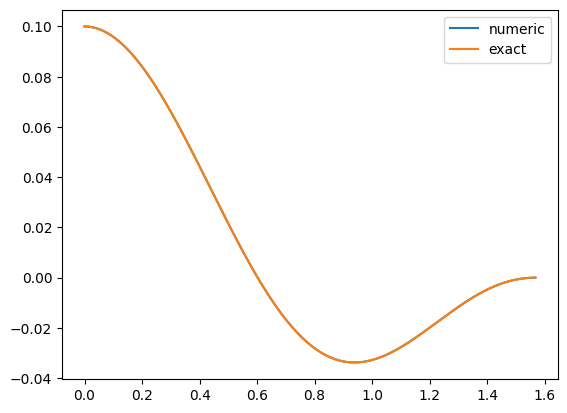

In [33]:
d = 2
l = 1
m = 0.5
solver = Bose_Star_Solver(d=d, l=l, kappa=0.0, el=0.0, mass=m, phi0=0.1, xrange=[0.001, 1.45])
phi_exact = Phi_Exact(d, l, m)

solver.shoot_for_omega(omega_range=[4, 5])
print("Exact omega", phi_exact.omega(1))

solver.get_star_profile()
phi_func = 0.1*phi_exact(1, solver.coords[:-1])
print("Maximal difference between numeric and exact solutions %.2e" % np.abs(phi_func - solver.fields[:-1,2]).max())

plt.plot(solver.coords[:-1], solver.fields[:-1,2], label='numeric')
plt.plot(solver.coords[:-1], phi_func, label='exact')
plt.legend()
plt.show()

### $d = 3$

Omega found by shooting 3.0811
Exact omega 3.08113883008419
Maximal difference between numeric and exact solutions 5.54e-07


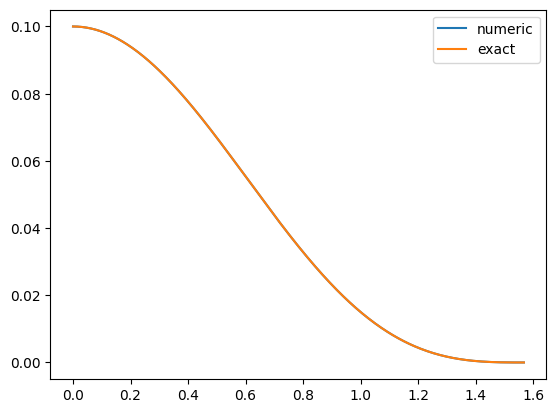

In [34]:
d = 3
l = 1
m = 0.5
solver = Bose_Star_Solver(d=d, l=l, kappa=0.0, el=0.0, mass=m, phi0=0.1)
phi_exact = Phi_Exact(d, l, m)

solver.shoot_for_omega(omega_range=[1,4])
print("Exact omega", phi_exact.omega(0))

solver.get_star_profile()
phi_func = 0.1*phi_exact(0, solver.coords[:-1])
print("Maximal difference between numeric and exact solutions %.2e" % np.abs(phi_func - solver.fields[:-1,2]).max())

plt.plot(solver.coords[:-1], solver.fields[:-1,2], label='numeric')
plt.plot(solver.coords[:-1], phi_func, label='exact')
plt.legend()
plt.show()

Omega found by shooting 5.0811
Exact omega 5.08113883008419
Maximal difference between numeric and exact solutions 3.20e-07


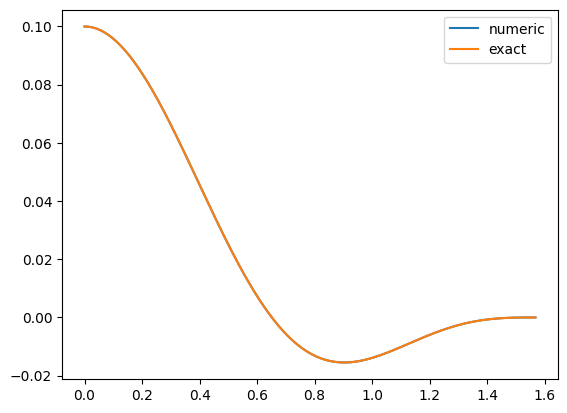

In [35]:
d = 3
l = 1
m = 0.5

solver = Bose_Star_Solver(d=d, l=l, kappa=0.0, el=0.0, mass=m, phi0=0.1, xrange=[0.001, 1.45])
phi_exact = Phi_Exact(d, l, m)

solver.shoot_for_omega(omega_range=[4,6])
print("Exact omega", phi_exact.omega(1))

solver.get_star_profile()
phi_func = 0.1*phi_exact(1, solver.coords[:-1])
print("Maximal difference between numeric and exact solutions %.2e" % np.abs(phi_func - solver.fields[:-1,2]).max())

plt.plot(solver.coords[:-1], solver.fields[:-1,2], label='numeric')
plt.plot(solver.coords[:-1], phi_func, label='exact')
plt.legend()
plt.show()

# Old

## CSV reader

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

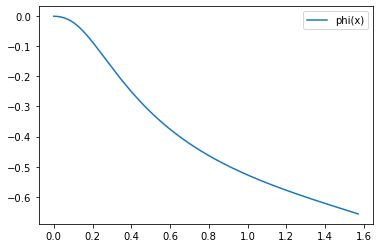

In [14]:
%matplotlib inline
df = pd.read_csv("Code/Data/solution.dat")
# plt.xlim(0,np.pi/2)
# plt.plot(df['x'], df['y0'], label='A(x)')
# plt.plot(df['x'], df['y1'], label='delta(x)')
plt.plot(df['x'], df['y4'], label='phi(x)')
# plt.plot(df['x'], 0.1*(np.cos(df['x']))**3.302, label='exact')
plt.legend()
plt.show()

## Cubic Solver

Solves equation $a x^3 + b x = c$

In [19]:
def solve_cubic(a,b,c, e=1.0e-4):
    if(np.abs(a) > e):
        det = np.sqrt((c/(2.0*a))**2 + (b/(3.0*a))**3)
        return (det + c/(2.0*a))**(1/3) - (det - c/(2.0*a))**(1/3)
    else:
        return c/b*(1.0 - a*c*c/(b*b*b) + 3*a*a*(c**4)/(b**6))

In [20]:
a0 = 3.0e-4
b0 = 4.0
c0 = 3.0
y = solve_cubic(a0, b0, c0)

print(y)
print(a0*(y**3) + b0*y - c0)

0.7499683633788408
-8.881784197001252e-16


In [21]:
a0 = 2.0
b0 = 4.0
c0 = 3.0
y = solve_cubic(a0, b0, c0)

print(y)
print(a0*(y**3) + b0*y - c0)

0.6268452758262435
-4.440892098500626e-16


## Old Tracer

In [35]:
tracer_zero = Tracer(d=3, l=1.0, el = 0.0, kappa=1.0, mass=0.0, xrange=[0.0001, 1.3])
tracer_zero.auto_trace((0.01, 2.0, 200), [2,4])

tracer_one = Tracer(d=3, l=1.0, el = 0.0, kappa=1.0, mass=0.0, xrange=[0.0001, 1.3])
tracer_one.auto_trace((0.01, 2.0, 200), [4, 6])

tracer_unit_mass_zero = Tracer(d=3, l=1.0, el = 0.0, kappa=1.0, mass=1.0, xrange=[0.0001, 1.3])
tracer_unit_mass_zero.auto_trace((0.01, 2.0, 200), [2, 4])

tracer_unit_mass_one = Tracer(d=3, l=1.0, el = 0.0, kappa=1.0, mass=1.0, xrange=[0.0001, 1.3])
tracer_unit_mass_one.auto_trace((0.01, 2.0, 200), [4, 6])

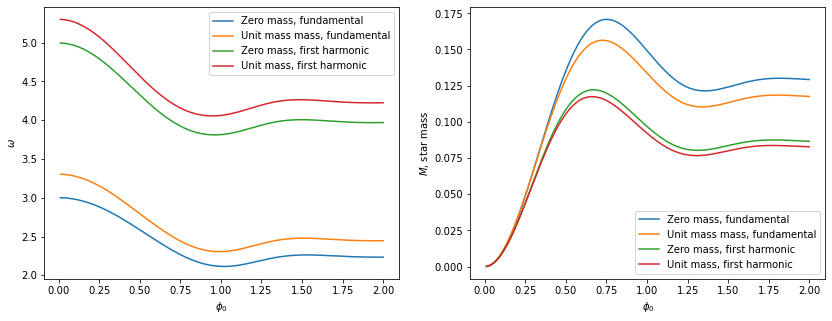

In [36]:
fig = plt.figure(figsize=(14,5))

ax = fig.add_subplot(121)
tracer_zero.plot_omega_curves(ax=ax, label='Zero mass, fundamental')
tracer_unit_mass_zero.plot_omega_curves(ax=ax, label='Unit mass mass, fundamental')

tracer_one.plot_omega_curves(ax=ax, label='Zero mass, first harmonic')
tracer_unit_mass_one.plot_omega_curves(ax=ax, label='Unit mass, first harmonic')
ax.legend()

ax = fig.add_subplot(122)
tracer_zero.plot_mass_curves(ax=ax, label='Zero mass, fundamental')
tracer_unit_mass_zero.plot_mass_curves(ax=ax, label='Unit mass mass, fundamental')

tracer_one.plot_mass_curves(ax=ax, label='Zero mass, first harmonic')
tracer_unit_mass_one.plot_mass_curves(ax=ax, label='Unit mass, first harmonic')
ax.legend()

# ax = fig.add_subplot(111)
# tracer_zero.plot_charge_curves(ax=ax, label='Zero mass, fundamental')
# tracer_unit_mass_zero.plot_charge_curves(ax=ax, label='Unit mass mass, fundamental')

# tracer_one.plot_charge_curves(ax=ax, label='Zero mass, first harmonic')
# tracer_unit_mass_one.plot_charge_curves(ax=ax, label='Unit mass, first harmonic')
# ax.legend()
# ax.set_ylim(-0.001,0.001)


plt.savefig("omega_vs_phi0.png", dpi=300)
plt.show()

Omega found by shooting 2.2619
Star mass is equal to 0.1241


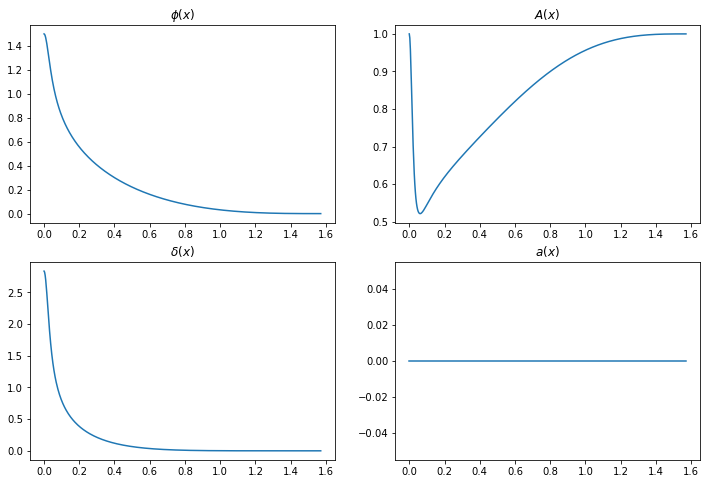

In [16]:
solver = Bose_Star_Solver(d=3, l=1.0, kappa=1.0, el=0.0, mass=0.0, phi0=1.5, xrange=[0.0001, 1.4])
# solver.shoot_for_omega(omega_range=[550, 1000])
# solver.shoot_for_omega(omega_range=[200, 300])
solver.shoot_for_omega(omega_range=[30, 60])
solver.get_star_profile()
solver.plot_star_profile()

plt.savefig("solution_phi0_1.5.png", dpi=300)
plt.show()

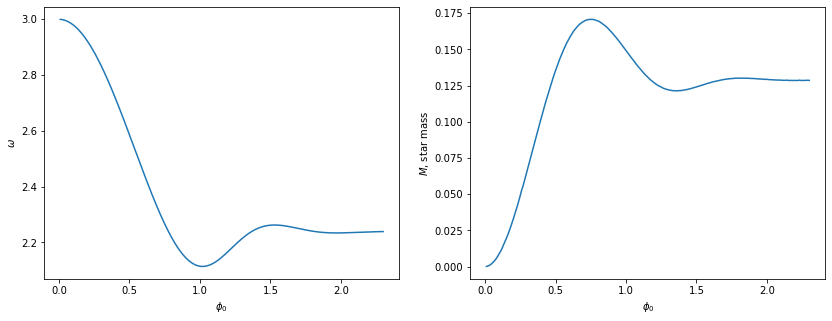

In [102]:
phi0_ranges = [(0.01, 0.5, 50), (0.51, 0.8, 30), (0.81, 1.0, 20), (1.01, 1.1, 10), (1.11, 1.20, 10), 
               (1.21, 1.30, 10), (1.31, 1.40, 10), (1.41, 1.50, 10), (1.51, 1.60, 10), (1.61, 1.70, 10),
               (1.71, 1.80, 10), (1.81, 1.90, 10), (1.91, 2.0, 10), (2.01, 2.1, 10), (2.11, 2.2, 10), (2.21, 2.3, 10)]
omega_ranges = [(2,4), (3,6), (5,9), (8,12), (11,16), (15,21), (20,30), (25,40),
                (35, 60), (50, 80), (70,120), (110,170), (160, 250), (220, 400), (350, 650), (550, 1000)]
tracer_zero = Tracer(d=3, l=1.0, el = 0.0, kappa=1.0, mass=0.0, xrange=[0.0001, 1.4])
tracer_zero.manual_trace(phi0_ranges, omega_ranges)

fig = plt.figure(figsize=(14,5))

ax = fig.add_subplot(121)
tracer_zero.plot_omega_curves(ax=ax, label='Zero mass, fundamental')

ax = fig.add_subplot(122)
tracer_zero.plot_mass_curves(ax=ax, label='Zero mass, fundamental')

# plt.savefig("mass_0_fundamental.png", dpi=300)
plt.show()